Chris McCarthy

DSC550

Professor Werner

Milestone 1 Project

Topic - Exploratory Analysis of EV Adoption and Market Trends

During my tenure in the data science program here at Bellevue, I have been focusing on electric vehicles for my project work. There is both a breadth and depth of available research that is publically vetted and sourced by the government and data science communities. Because of this, I am confident in the datasets as I move forward into data exploration and analysis. That being said, I have been aiming to explore different aspects of the EV market so I can grasp a deeper and more widespread understanding of the landscape. The scope of electric vehicle research is wide so my goal for each project is to take a slice of it and perform meaningful data exploration and analysis.

For DSC550, my interest will build off of previous work I did for a project in DSC540. In the past, I was studying EV density by city in Washington state. I was also looking at charging station availability. However, there is plenty more I would like to dig into and research. For this milestone project, I would like to focus on EV Adoption and market trends in Washington state. Instead of just density of EVs, I want to look at growth over the years. I also want to look at who dominates the EV market, and if consumers are trending towards BEV (battery electric vehicles) versus PHEV (plug-in hybrids). Finally, I'll look at CAFV Eligibility (clean fuel incentives) and how it distributes in WA state.

My purpose is to assess the EV landscape in WA state and observe market trends based on the dataset. By doing so, I hope to provide real-world business value to invested companies. I am also curious as to the landscape of the competitive market in WA state and if there is parity between manufacturers. If not, why not? I am sure my questions may evolve or change as I investigate further.

Dataset: electric_vehicle_population_data.csv

Initial Graphs and Visualizations

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data/Electric_Vehicle_Population_Data.csv')

df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271113 entries, 0 to 271112
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         271113 non-null  object 
 1   County                                             271103 non-null  object 
 2   City                                               271103 non-null  object 
 3   State                                              271113 non-null  object 
 4   Postal Code                                        271103 non-null  float64
 5   Model Year                                         271113 non-null  int64  
 6   Make                                               271113 non-null  object 
 7   Model                                              271113 non-null  object 
 8   Electric Vehicle Type                              271113 non-null  object

Based on the info, there are variables that look useful for my exploration. They include: model year, make, electric vehicle type and CAFV eligibility.

1. Data Cleaning

In [3]:
df.isnull().sum()
df.duplicated().sum()
df = df.drop_duplicates()

df.shape

(271113, 16)

In [4]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("(", "").str.replace(")", "")

df.columns

Index(['vin_1-10', 'county', 'city', 'state', 'postal_code', 'model_year',
       'make', 'model', 'electric_vehicle_type',
       'clean_alternative_fuel_vehicle_cafv_eligibility', 'electric_range',
       'legislative_district', 'dol_vehicle_id', 'vehicle_location',
       'electric_utility', '2020_census_tract'],
      dtype='object')

Made lowercase for best practice.

2. Variables of Interest

In [5]:
df[["model_year", "make", "electric_vehicle_type", 
    "clean_alternative_fuel_vehicle_cafv_eligibility"]].head()

,model_year,make,electric_vehicle_type,clean_alternative_fuel_vehicle_cafv_eligibility
0,2018,TESLA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible
1,2011,NISSAN,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible
2,2011,NISSAN,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible
3,2020,CHEVROLET,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible
4,2020,KIA,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range


In [6]:
df["model_year"].describe()

count    271113.000000
mean       2021.995068
std           3.056730
min        1999.000000
25%        2021.000000
50%        2023.000000
75%        2024.000000
max        2026.000000
Name: model_year, dtype: float64

3. Graph 1 - EV Registration by Model Year in WA State

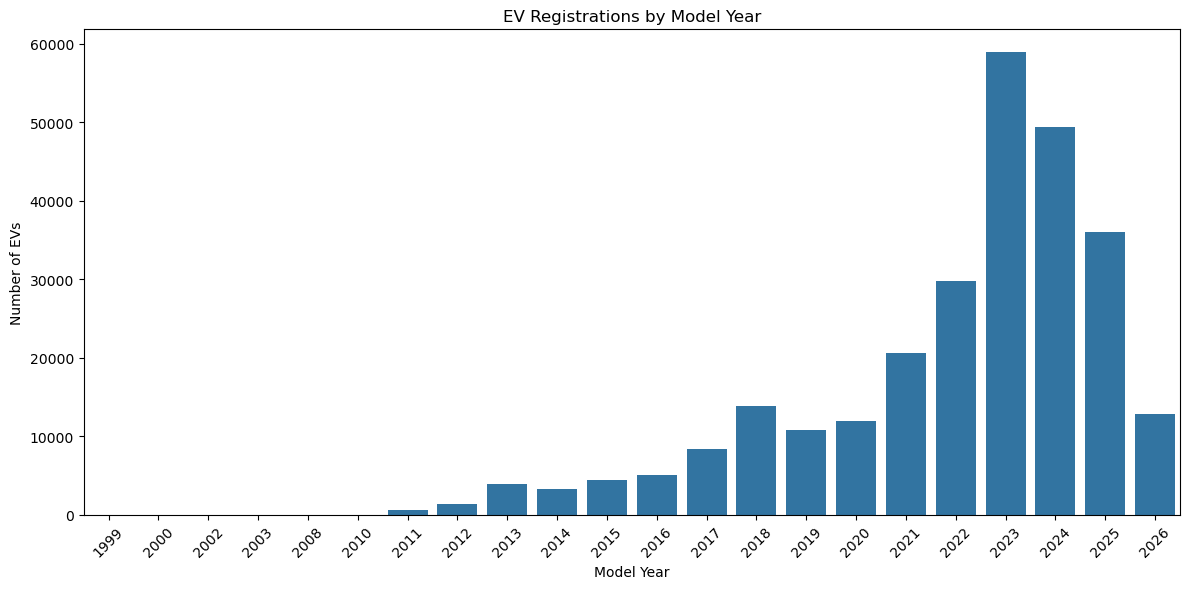

In [7]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x="model_year")

plt.title("EV Registrations by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Number of EVs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This is a great visual for demonstrating the increasing popularity of EVs in WA state, especially from 2021 onward. There is a meaningful peak in 2023 followed by a slow descent in 2024 and 2025. Of course, 2026 is ongoing so the data is incomplete for that column.

4. Graph 2 - Top 10 EV Manufacturers in WA State

In [8]:
top_makes = df["make"].value_counts().head(10)

top_makes

make
TESLA         110537
CHEVROLET      19044
NISSAN         15955
FORD           14938
KIA            13617
TOYOTA         11381
BMW            11202
HYUNDAI         9828
RIVIAN          8511
VOLKSWAGEN      7368
Name: count, dtype: int64

Tesla is the overwhelming leader in EV popularity in WA state at a staggering 110537. The second most is Chevrolet at 19044 and third is Nissan at 15955.

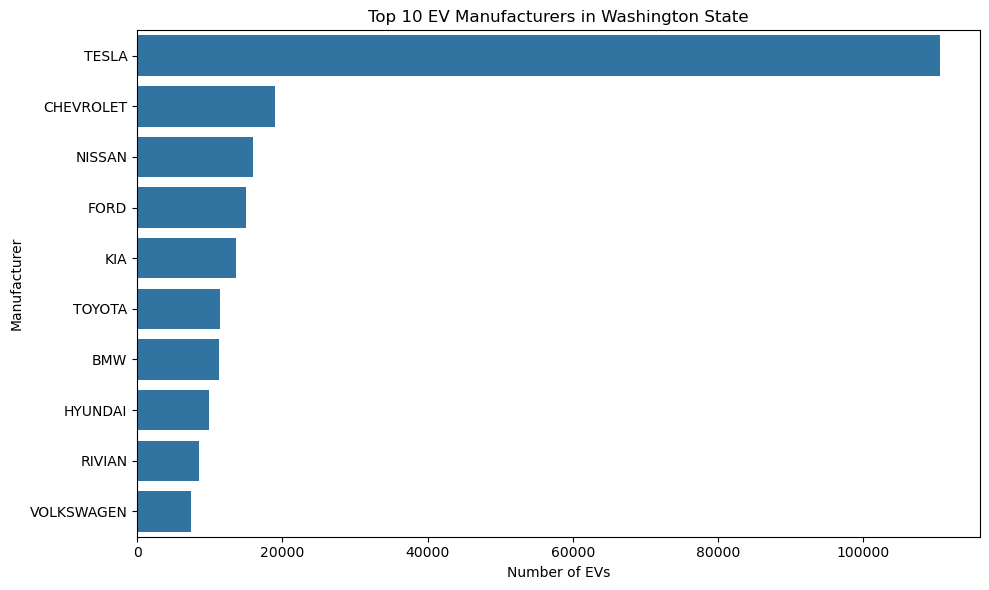

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(x=top_makes.values, y=top_makes.index)

plt.title("Top 10 EV Manufacturers in Washington State")
plt.xlabel("Number of EVs")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()

The graph does a good job of visually demonstrating the disparity between manufacturers.

5. Graph 3 - BEV vs PHEV Adoption over Time in WA State

In [10]:
ev_type_by_year = df.groupby(["model_year", "electric_vehicle_type"]).size().reset_index(name="count")

ev_type_by_year.head()

,model_year,electric_vehicle_type,count
0,1999,Battery Electric Vehicle (BEV),2
1,2000,Battery Electric Vehicle (BEV),8
2,2002,Battery Electric Vehicle (BEV),1
3,2003,Battery Electric Vehicle (BEV),1
4,2008,Battery Electric Vehicle (BEV),20


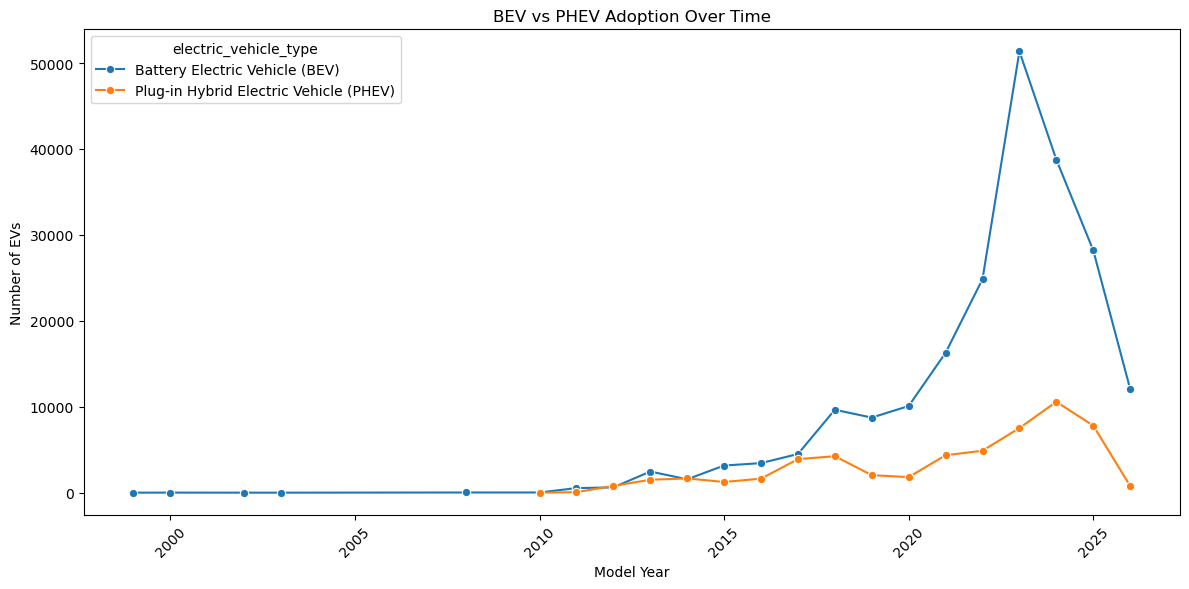

In [11]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=ev_type_by_year,
    x="model_year",
    y="count",
    hue="electric_vehicle_type",
    marker="o"
)

plt.title("BEV vs PHEV Adoption Over Time")
plt.xlabel("Model Year")
plt.ylabel("Number of EVs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This graph is interesting because it demonstrates a similar positive trend up through 2023 followed by a similar fall-off in the years after. Based on the visual and the data, BEVs experience a much higher peak and a steeper drop-off. PHEVs follow a similar pattern which suggests to me that consumer interest is either more invested in BEVs as a whole, or PHEV registration performance is closely tied to BEV popularity in the given year. Of course, there are other possibilities as well but these two initial assumptions are a good place to start.

6. Graph 4 - CAFV Eligibility Distribution in WA State

In [12]:
cafv_counts = df["clean_alternative_fuel_vehicle_cafv_eligibility"].value_counts()

cafv_counts

clean_alternative_fuel_vehicle_cafv_eligibility
Eligibility unknown as battery range has not been researched    170815
Clean Alternative Fuel Vehicle Eligible                          76207
Not eligible due to low battery range                            24091
Name: count, dtype: int64

Immediately, eligibility being unknown as the majority stands out. I will keep this in mind as I decide on how to approach this problem.

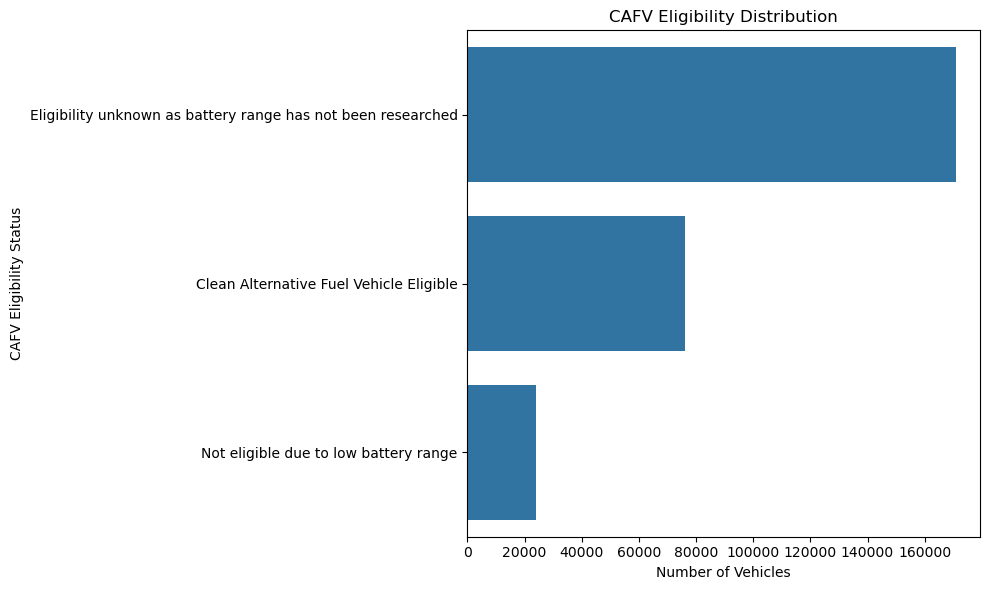

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(x=cafv_counts.values, y=cafv_counts.index)

plt.title("CAFV Eligibility Distribution")
plt.xlabel("Number of Vehicles")
plt.ylabel("CAFV Eligibility Status")
plt.tight_layout()
plt.show()

Between eligible and ineligible vehicles, a majority of known vehicles qualify for CAFV at 76207. The number of vehicles that do not quality counts at 24091. There is a large number of unknowns at 170815. This is concerning because that is an overwhelming part of the dataset value for this column. I do want to explore this area further but I am also considering dropping it in favor of a better documented factor.

Conclusion

Based on the graphical analysis performed, I have gained some insights towards my driving questions from the dataset. First and foremost, EV adoption in WA state has trended positively through 2023 from its start around 2011. In fact, 2023 was a significant peak in EV registration in the state. The decline in following years could be due to a number of factors, of which I'll have to research and explore. Second, there is general parity between manufacturers in WA state except for Tesla, which overwhelmingly dominates the market. I am unsure as to why, so this requires further inquiry. Third, the trend of EV and PHEV adoptions in WA state match the pattern shown by the initial first bar graph, with both types of vehicles enjoying positive growth through 2023, followed by a decline. Finally, CAFV eligibility is based on battery range and a roughly 75% majority of EV owners enjoy CAFV incentives while 25% do not. A significant number of registrations lack the necessary information to disclose whether or not they quality for CAFV, which is problematic.

Overall, I am confident in this graphical analysis as first steps in my exploration of EV adoption and market trends in WA state. I can continue to build on this information and hope to further explore the business landscape within WA state.

MILESTONE 2

Key considerations:

-Drop any features that are not useful for your model building and explain why they are not useful.

-Perform any data extraction/selection steps.

-Transform features if necessary.

-Engineer new useful features.

-Deal with missing data (do not just drop rows or columns without justifying this).

-Create dummy variables if necessary.

1. Engineer new target

After milestone 1, I've decided to create a new target feature for my research. I think comparing manufacturers and what goes into their adoption rates will be a meaningful exploration

In [14]:
top_makes = df["make"].value_counts().head(5)
top_makes

make
TESLA        110537
CHEVROLET     19044
NISSAN        15955
FORD          14938
KIA           13617
Name: count, dtype: int64

In [15]:
#new target

top_manufacturers = top_makes.index

df["high_adoption_manufacturer"] = (
    df["make"]
    .isin(top_manufacturers)
    .astype(int)
)

Manufacturers with highest adoption rate / registration count are labeled as top_manufacturers. My goal is to determine characteristics and factors that go into high-adoption rate in WA state.

2. Drop features unnecessary for model building

In [16]:
drop_cols = [
    "vin_1-10",
    "dol_vehicle_id",
    "vehicle_location",
    "2020_census_tract",
    "clean_alternative_fuel_vehicle_cafv_eligibility"
]

df = df.drop(columns=drop_cols)

For my exploration, these features are unnecessary. This is because all of this information is primarily used for location data or identification. For top manufacturer predictors, these features have no value. Also, I mentioned this earlier in milestone 1, but the sheer number of unknown values for CAFV eligilibility limits its usefulness. Over 63% of the column is considered unknown. For that reason, I have decided to drop it as well.

3. Deal with missing data

In [17]:
df.isnull().sum()

county                         10
city                           10
state                           0
postal_code                    10
model_year                      0
make                            0
model                           0
electric_vehicle_type           0
electric_range                  7
legislative_district          659
electric_utility               10
high_adoption_manufacturer      0
dtype: int64

In [18]:
#addressing missing values for county and city

df["county"] = df["county"].fillna("Unknown")
df["city"] = df["city"].fillna("Unknown")

In [19]:
#addressing missing values for legislative district

df["legislative_district"] = (
    df["legislative_district"]
    .fillna(df["legislative_district"].median())
)

In [20]:
# addressing missing values for electric range

print("Missing electric_range values before:", df["electric_range"].isnull().sum())

df = df.dropna(subset=["electric_range"])

print("Missing electric_range values after:", df["electric_range"].isnull().sum())

Missing electric_range values before: 7
Missing electric_range values after: 0


Postal code and electric utility are unnecessary to my exploration. I will leave them as is. However, I may circle back to county, city, and legislative district in the future, so I have filled their missing values. Also, since electric_range had a neglible number of missing values, I have removed them entirely (missing 7 out of 271,113 observations which is less than .01%). Data quality is maintained.

4. Engineer new feature

In [21]:
#looking at vehicle age

df["vehicle_age"] = 2026 - df["model_year"]

df[["model_year", "vehicle_age"]].head()

,model_year,vehicle_age
0,2018,8
1,2011,15
2,2011,15
3,2020,6
4,2020,6


I want to see if age plays into adoption rate, especially given market environments over the years. I am curious to see the comparison between manufacturers depending on vehicle age, and if Tesla's popularity has more to do with timing than features.

5. Simplifying BEV and PHEV with binary encoding

In [22]:
df["is_bev"] = (
    df["electric_vehicle_type"]
    .str.contains("BEV")
    .astype(int)
)

For ease of modeling, BEV is 1 and PHEV is 0.

6. More Finalized Feature Selection

In [23]:
selected_cols = [
    "high_adoption_manufacturer",
    "vehicle_age",
    "electric_range",
    "is_bev"
]

model_df = df[selected_cols]

model_df.head()
model_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 271106 entries, 0 to 271112
Data columns (total 4 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   high_adoption_manufacturer  271106 non-null  int32  
 1   vehicle_age                 271106 non-null  int64  
 2   electric_range              271106 non-null  float64
 3   is_bev                      271106 non-null  int32  
dtypes: float64(1), int32(2), int64(1)
memory usage: 8.3 MB


I think these features will perform the best for my exploration topic. All of them contribute as more concrete vehicle characteristics. The columns I dropped earlier in the milestone were more focused on geography and identification.

MILESTONE 3

In [24]:
model_df["high_adoption_manufacturer"].value_counts(normalize=True)

high_adoption_manufacturer
1    0.642151
0    0.357849
Name: proportion, dtype: float64

Since the distribution between the top 5 manufacturers and everyone else is roughly 65% vs 35%, I think it's safe to proceed. It is somewhat imbalanced but because there is enough representation between the classes, I can continue building a model with a stratified train/test split

1. Model Building for Binary Classification Problem

Decision Tree Classifier

In [25]:
#x defined
X = model_df.drop("high_adoption_manufacturer", axis=1)

#y defined
y = model_df["high_adoption_manufacturer"]

In [26]:
from sklearn.model_selection import train_test_split


#training model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Dataset split into training and test sets, at an 80/20 ratio. I'm using stratification to preserve distribution between high and low adoption manufacturers (top 5 manufacturers vs everyone else)

In [27]:
from sklearn.tree import DecisionTreeClassifier

#building decision tree
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

tree_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

4. Prediction

In [28]:
y_pred = tree_model.predict(X_test)

5. Evaluation

In [29]:
#metrics report

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy: 0.771956032606691

Classification Report
              precision    recall  f1-score   support

           0       0.87      0.43      0.57     19403
           1       0.75      0.96      0.84     34819

    accuracy                           0.77     54222
   macro avg       0.81      0.70      0.71     54222
weighted avg       0.79      0.77      0.75     54222



Analysis of Output

The accuracy is 77% which is decent for an initial model with three predictors

Class 1 recall is most impressive at 96%, indicating the model is effective at identifiying high-adoption manufacturers

Class 0 recall is only 43%, meaning the model struggles to identify lower-adoption manufacturers

6. Confusion Matrix

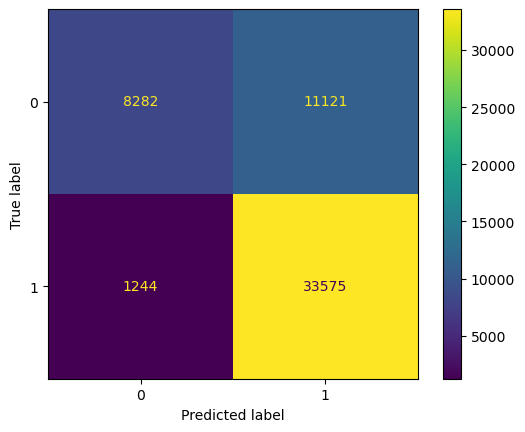

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

#confusion matrix with visual
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()

7. Feature Importance

In [31]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree_model.feature_importances_
})

feature_importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
2,is_bev,0.565346
0,vehicle_age,0.251246
1,electric_range,0.183408


The strongest predictor of the three is: is_bev at .565. In other words, whether or not the vehicle is full battery electric.

Followed by vehicle_age at .25, and electric_range at .18

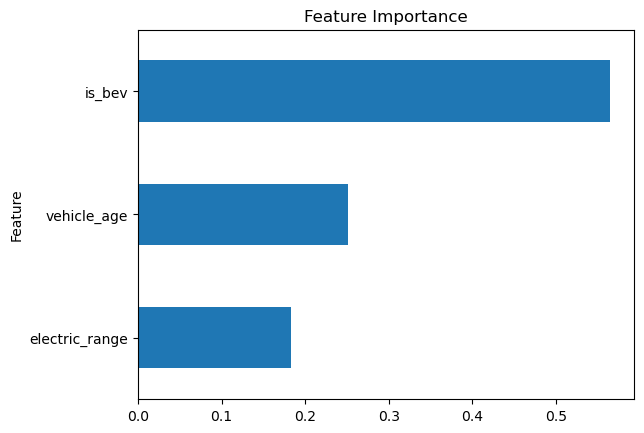

In [32]:
feature_importance.sort_values(
    by="Importance",
    ascending=True
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Feature Importance")
plt.show()

Visualization of feature importance

Current Conclusion

Overall, milestone 3 has been helpful in demonstrating the effectiveness of the decision tree classifier as a model. The model achieved a 77% accuracy, suggesting selected features offered predictive value. It has also provided information on three predictors and their efficacy when it comes to high-adopotion manufacturers vs everyone else. Current findings suggest that whether or not a vehicle is full battery electric is the biggest indicator of high-adoption rate. This is followed by vehicle age, and then electric range. This means high-adoption manufacturers in WA state can be strongly associated with making BEVs, along with having potentially better timing for market entry and offering newer vehicles compared to other manufacturers.

Final Project Code Additions

In order to add depth to my project, I would like to compare the decision tree classifier metrics with a random forest classifier. Doing model comparison may shed some light on performance and reliability

Random Forest Classifier

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.8073291283980673
              precision    recall  f1-score   support

           0       0.97      0.47      0.64     19403
           1       0.77      0.99      0.87     34819

    accuracy                           0.81     54222
   macro avg       0.87      0.73      0.75     54222
weighted avg       0.84      0.81      0.79     54222



RF Feature Importance

In [34]:
#ranking feature importance to RF
rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
1,electric_range,0.504456
2,is_bev,0.289184
0,vehicle_age,0.206360


Comparison Table of Decision Tree vs Random Forest

In [35]:
#comparing model accuracy
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

comparison

,Model,Accuracy
0,Decision Tree,0.771956
1,Random Forest,0.807329


There's a couple really interesting points here. First, the random forest model performed more accurately than the decision tree by about 3.5%, so that's an improvement. Second, the feature importance changed between the two models. The decision tree classifier prioritized the importance of is_bev at .565. However, the random forest classifier prioritized electric_range at .50 as most important. This is interesting because both models were similar in accuracy but weighed the combination of factors differently.

I think this goes to show that model comparison is meaningful because they offer different perspectives on the data. The combination and comparison of their outputs suggests that EV adoption is a mix of is_bev, electric_range, and vehicle_age at varying levels of importance depending on the modeling. This means no single characteristic is outweighing the other, and could mean that market timing and other external factors could be playing a major role as well.

Overall, I'm pleased with the addition of the random forest classifier because it offered new insight. It also combines multiple decision trees to reduce overfitting and improves predictive performance.